<a href="https://colab.research.google.com/github/jishnujs1990/Study/blob/master/RevenueVision_Final_Project_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Import packages

In [1]:
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'seaborn': 'seaborn', 'sklearn': 'scikit-learn', 'joblib': 'joblib',
    'xgboost': 'xgboost', 'statsmodels': 'statsmodels'
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
if importlib.util.find_spec('torch') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'torch',
                           '--index-url', 'https://download.pytorch.org/whl/cpu'])
print('Packages are available.')

Packages are available.


In [2]:
from pathlib import Path
import re, json, sqlite3, random, warnings, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import torch
from torch import nn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor
from IPython.display import display, Markdown
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score

SEED = 42
HORIZON = 4     # Predict the next four supplied buckets
LOOKBACK = 26   # Read the last 26 buckets
SEASON = 53     # Supplied dataset convention, not ISO weeks
EARLIEST_ORIGIN = SEASON + 13
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

## 2. Read your CSV

In [3]:
input_path = "/content/Global_Superstore_Estimated_Dates.csv"
CSV_ENCODING = 'utf-8-sig'

# Read the CSV file
raw = pd.read_csv(input_path, encoding=CSV_ENCODING)

# Print summary and display data
print(f'Loaded {len(raw):,} rows and {len(raw.columns)} columns')

display(raw.head())

Loaded 51,290 rows and 32 columns


,Category,City,Country,Customer ID,Customer Name,Discount,Market,ji_lu-shu,Order Date,Order ID,Order Priority,Product ID,Product Name,Profit,Quantity,Region,Row ID,Sales,Segment,Ship Date,Ship Mode,Shipping Cost,State,Sub-Category,Year,Market2,weeknum,Original Order Date,Original Ship Date,Dates Are Synthetic,Order Date Method,Ship Date Method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,Second Class,4.37,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,Standard Class,1.81,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,Standard Class,4.59,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,Standard Class,1.32,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 3. Inspect the input
One row is a transaction **line**, not necessarily one order. Check types, missing values,
exact duplicates, and sample values before cleaning.

In [4]:
raw.info()
display(pd.DataFrame({'type': raw.dtypes.astype(str),
                      'missing': raw.isna().sum(),
                      'unique_values': raw.nunique()}))
print('Exact duplicate rows:', raw.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Category             51290 non-null  object 
 1   City                 51290 non-null  object 
 2   Country              51290 non-null  object 
 3   Customer ID          51290 non-null  object 
 4   Customer Name        51290 non-null  object 
 5   Discount             51290 non-null  float64
 6   Market               51290 non-null  object 
 7   ji_lu-shu            51290 non-null  int64  
 8   Order Date           51290 non-null  object 
 9   Order ID             51290 non-null  object 
 10  Order Priority       51290 non-null  object 
 11  Product ID           51290 non-null  object 
 12  Product Name         51290 non-null  object 
 13  Profit               51290 non-null  float64
 14  Quantity             51290 non-null  int64  
 15  Region               51290 non-null 

,type,missing,unique_values
Category,object,0,3
City,object,0,3636
Country,object,0,147
Customer ID,object,0,4873
Customer Name,object,0,795
Discount,float64,0,27
Market,object,0,7
ji_lu-shu,int64,0,1
Order Date,object,0,212
Order ID,object,0,25035


Exact duplicate rows: 0


## 4. Clean and validate

In [5]:
# Step 1: Create a copy of the original data
df = raw.copy()

# Step 2: Clean column names
# Example: "Customer Name" becomes "customer_name"
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Step 3: Remove duplicate rows
df = df.drop_duplicates()

# Step 4: Convert columns to numeric format
numeric_cols = ['sales', 'profit', 'quantity', 'discount',
                'shipping_cost', 'year', 'weeknum']

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Step 5: Fill missing numeric values
df['discount'] = df['discount'].fillna(0)
df['shipping_cost'] = df['shipping_cost'].fillna(df['shipping_cost'].median())

# Step 6: Remove rows with missing important values
df = df.dropna(subset=['sales', 'profit', 'quantity', 'year', 'weeknum'])

# Step 7: Remove invalid sales and quantity records
df = df[(df['sales'] >= 0) & (df['quantity'] > 0)]

# Step 8: Fill missing text values
df = df.fillna('Unknown')

# Step 9: Display cleaned data
print("Total cleaned rows:", len(df))
df.head()

Total cleaned rows: 51290


,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,ship_mode,shipping_cost,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,Second Class,4.37,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,Standard Class,0.94,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,Standard Class,1.81,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,Standard Class,4.59,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,Standard Class,1.32,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay


## 5. Create the approved estimated dates

In [6]:
# Step 1: Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# Step 2: Convert existing dates into datetime format
df['order_date'] = pd.to_datetime(df['order_date'])
df['ship_date'] = pd.to_datetime(df['ship_date'])

# Step 3: Extract month and quarter for analysis
df['month'] = df['order_date'].dt.month
df['quarter'] = df['order_date'].dt.quarter
# Calculate and store df['estimated_month'] for the following steps.
df['estimated_month'] = df.order_date.dt.strftime('%Y-%m')
# Calculate and store df['estimated_quarter'] for the following steps.
df['estimated_quarter'] = df.order_date.dt.quarter


# Step 4: Check the result
df[['order_date', 'ship_date', 'year', 'weeknum', 'month', 'quarter']].head()

,order_date,ship_date,year,weeknum,month,quarter
0,2011-01-08,2011-01-12,2011,2,1,1
1,2011-01-22,2011-01-26,2011,4,1,1
2,2011-08-06,2011-08-10,2011,32,8,3
3,2011-08-06,2011-08-10,2011,32,8,3
4,2011-10-01,2011-10-05,2011,40,10,4


## 6. Keys, outlier flags, and category encoding
Raw Order IDs are reused. We count composite orders using Order ID + Customer ID + Country + Year + bucket.
Product keys also include Product Name. IQR outliers are **flagged and retained**.
Category codes are descriptive labels, not ordered numerical inputs to the revenue forecast.

In [7]:
order_cols = ['order_id', 'customer_id', 'country', 'year', 'weeknum']
df['order_key'] = df[order_cols].astype(str).agg('|'.join, axis=1)
df['product_key'] = df[['product_id', 'product_name']].astype(str).agg('|'.join, axis=1)
q1, q3 = df.sales.quantile([0.25, 0.75])
iqr = q3 - q1
df['sales_iqr_outlier'] = (df.sales < q1 - 1.5*iqr) | (df.sales > q3 + 1.5*iqr)
df['log1p_sales'] = np.log1p(df.sales)
df['profit_margin'] = df.profit.div(df.sales.where(df.sales > 0))
encoder = LabelEncoder()
df['category_code'] = encoder.fit_transform(df.category)
quality = {
    'input_rows': len(raw), 'clean_rows': len(df),
    'outliers_retained': int(df.sales_iqr_outlier.sum()),
    'negative_profit_lines': int((df.profit < 0).sum()),
    'zero_sales_lines': int((df.sales == 0).sum()),
    'reused_order_ids': int((df.groupby('order_id').order_key.nunique() > 1).sum()),
    'dates_are_synthetic': True
}
display(pd.Series(quality))
print('Category labels:', dict(enumerate(encoder.classes_)))
display(df[['sales', 'profit', 'quantity', 'discount', 'shipping_cost']].describe())

,0
input_rows,51290
clean_rows,51290
outliers_retained,5655
negative_profit_lines,12544
zero_sales_lines,1
reused_order_ids,660
dates_are_synthetic,True


Category labels: {0: 'Furniture', 1: 'Office Supplies', 2: 'Technology'}


,sales,profit,quantity,discount,shipping_cost
count,51290.000000,51290.000000,51290.000000,51290.000000,51290.000000
mean,246.498440,28.610982,3.476545,0.142908,26.375818
std,487.567175,174.340972,2.278766,0.212280,57.296810
min,0.000000,-6599.978000,1.000000,0.000000,0.002000
25%,31.000000,0.000000,2.000000,0.000000,2.610000
50%,85.000000,9.240000,3.000000,0.000000,7.790000
75%,251.000000,36.810000,5.000000,0.200000,24.450000
max,22638.000000,8399.976000,14.000000,0.850000,933.570000


## 7. Aggregate into the forecasting series
Group transaction lines into total revenue per Year/weeknum bucket.
For this project we require all 212 supplied buckets from 2011–2014; missing buckets are not silently treated as zero.
The 53-bucket seasonal convention has irregular calendar spacing at year boundaries.

In [8]:
weekly = (df.groupby(['year', 'weeknum'], as_index=False)
          .agg(sales=('sales', 'sum'), profit=('profit', 'sum'),
               quantity=('quantity', 'sum'), order_count=('order_key', 'nunique'),
               estimated_date=('order_date', 'min'))
          .sort_values(['year', 'weeknum']).reset_index(drop=True))
weekly['period_index'] = np.arange(len(weekly))
expected = [(year, week) for year in range(2011, 2015) for week in range(1, 54)]
observed = list(weekly[['year', 'weeknum']].itertuples(index=False, name=None))
if observed != expected:
    raise ValueError('This notebook expects the complete 2011–2014, 53-bucket-per-year file. '
                     'Review missing/extra buckets before changing the evaluation design.')
y = weekly.sales.to_numpy(dtype=float)
assert np.isclose(y.sum(), df.sales.sum())
print(f'{len(df):,} lines become {len(weekly)} forecasting periods.')
display(weekly.head())

51,290 lines become 212 forecasting periods.


,year,weeknum,sales,profit,quantity,order_count,estimated_date,period_index
0,2011,1,808,198.87300,19,4,2011-01-01,0
1,2011,2,25329,2872.82744,262,49,2011-01-08,1
2,2011,3,27840,2678.94898,410,53,2011-01-15,2
3,2011,4,19783,2967.36194,313,46,2011-01-22,3
4,2011,5,17044,-1024.28260,364,53,2011-01-29,4


## 8. Calculate business KPIs
Revenue = sum of line Sales. Do not multiply Sales by Quantity again.
Average order value uses composite **orders**, not transaction-line count.
Overall margin = total Profit / total Sales.

In [9]:
total_sales = float(df.sales.sum())
if total_sales <= 0:
    raise ValueError('Positive total revenue is required for the ratio analyses.')
kpis = {
    'Revenue': total_sales,
    'Profit': float(df.profit.sum()),
    'Profit margin (%)': float(df.profit.sum() / total_sales * 100),
    'Orders': int(df.order_key.nunique()),
    'Average order value': total_sales / df.order_key.nunique(),
    'Customers': int(df.customer_id.nunique()),
    'Quantity': int(df.quantity.sum())
}
display(pd.Series(kpis).to_frame('Value'))
annual = df.groupby('year').agg(revenue=('sales', 'sum'), profit=('profit', 'sum'))
annual['growth_pct'] = annual.revenue.pct_change() * 100
category = df.groupby('category').agg(revenue=('sales', 'sum'), profit=('profit', 'sum'))
regions = df.groupby('region').sales.sum().sort_values(ascending=False)
display(annual)
display(category)

,Value
Revenue,1.264290e+07
Profit,1.467457e+06
Profit margin (%),1.160696e+01
Orders,2.575400e+04
Average order value,4.909103e+02
Customers,4.873000e+03
Quantity,1.783120e+05


,revenue,profit,growth_pct
year,,,
2011,2259511,248940.81154,NaN
2012,2677493,307415.27910,18.498781
2013,3405860,406935.23018,27.203320
2014,4300041,504165.97046,26.254191


,revenue,profit
category,,
Furniture,4110884,285204.72380
Office Supplies,3787330,518473.83430
Technology,4744691,663778.73318


## 9. Explore distributions and relationships
These charts run directly on the cleaned data. High-value Sales are preserved.
The scatter uses a reproducible sample for readability; correlations use all lines.
Correlation describes association and does not establish cause.

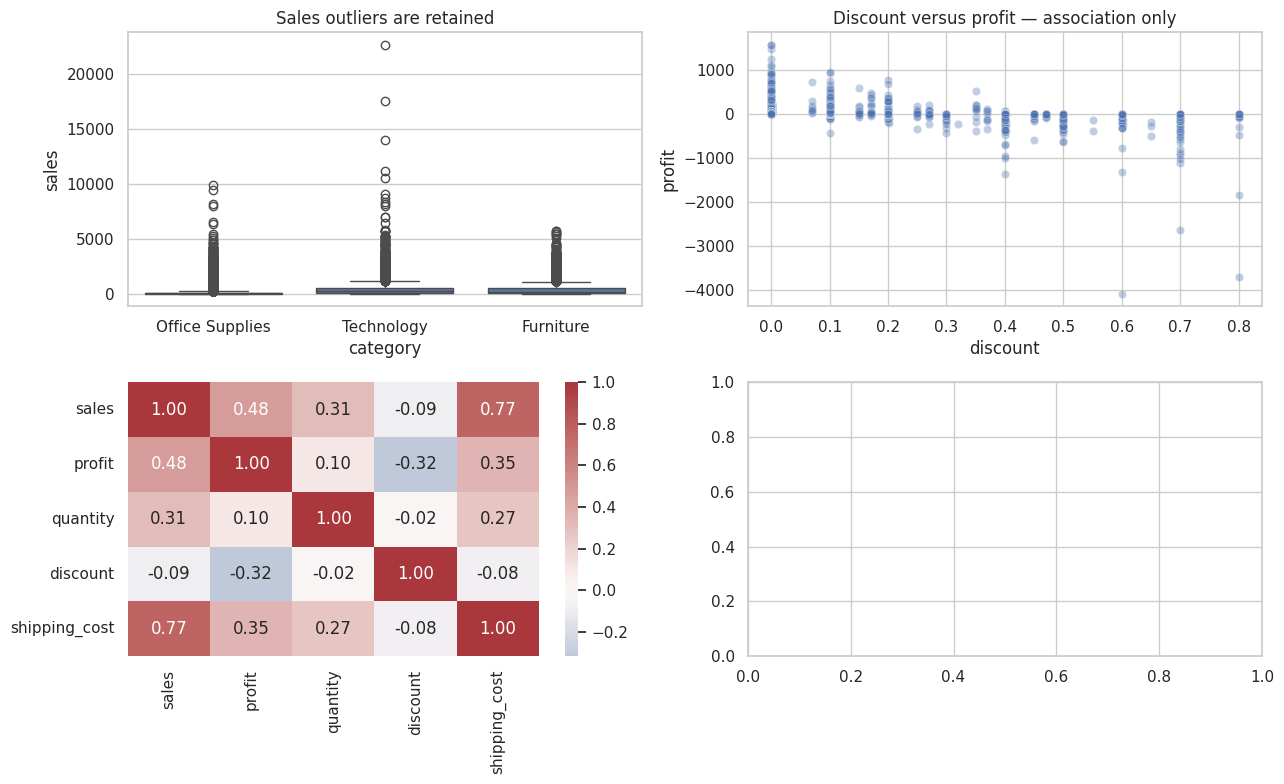

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
sns.boxplot(data=df, x='category', y='sales', ax=axes[0, 0])
axes[0, 0].set_title('Sales outliers are retained')
sample = df.sample(min(3000, len(df)), random_state=SEED)
sns.scatterplot(data=sample, x='discount', y='profit', alpha=0.35, ax=axes[0, 1])
axes[0,1].set_title('Discount versus profit — association only')
correlation = df[['sales', 'profit', 'quantity', 'discount', 'shipping_cost']].corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1, 0])
fig.tight_layout()
eda_figure = fig
plt.show()

In [11]:
df

,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,...,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method,month,quarter,estimated_month,estimated_quarter,order_key,product_key,sales_iqr_outlier,log1p_sales,profit_margin,category_code
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,...,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,2011-01,1,CA-2011-130813|LS-172304|United States|2011|2,OFF-PA-10002005|Xerox 225,False,2.995732,0.491116,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,...,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,2011-01,1,CA-2011-148614|MV-174854|United States|2011|4,"OFF-PA-10002893|Wirebound Service Call Books, ...",False,2.995732,0.489095,1
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,2011-08,3,CA-2011-118962|CS-121304|United States|2011|32,"OFF-PA-10000659|Adams Phone Message Book, Prof...",False,3.091042,0.468657,1
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,2011-08,3,CA-2011-118962|CS-121304|United States|2011|32,OFF-PA-10001144|Xerox 1913,False,4.718499,0.479827,1
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,...,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,10,4,2011-10,4,CA-2011-146969|AP-109154|United States|2011|40,OFF-PA-10002105|Xerox 223,False,1.945910,0.518400,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10000632,Satellite Sectional Post Binders,22.5732,2,West,33646,69,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,2014-12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10000632|Satellite Sectional Post Binders,False,4.248495,0.327148,1
51286,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10004187,Staples,3.1584,6,West,33645,9,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,2014-12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10004187|Staples,False,2.302585,0.350933,1
51

## 10. Explore annual and supplied-bucket trends
Annual category totals use the observed Year field. The bucket plot shows supplied ordering.
The monthly plot uses estimated dates and cannot verify real monthly seasonality.

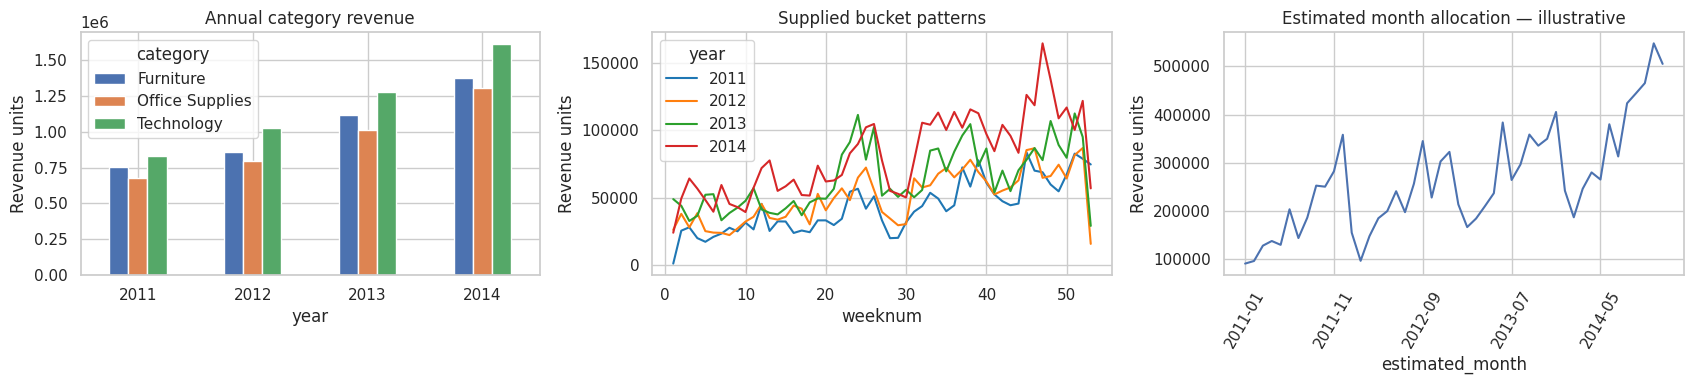

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
annual_category = df.pivot_table(index='year', columns='category', values='sales', aggfunc='sum')
annual_category.plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Annual category revenue')
sns.lineplot(data=weekly, x='weeknum', y='sales', hue='year', palette='tab10', ax=axes[1])
axes[1].set_title('Supplied bucket patterns')
monthly = df.groupby('estimated_month').sales.sum()
monthly.plot(ax=axes[2])
axes[2].set_title('Estimated month allocation — illustrative')
axes[2].tick_params(axis='x', rotation=60)
for ax in axes:
    ax.set_ylabel('Revenue units')
fig.tight_layout()
trend_figure = fig
plt.show()

In [13]:
db = sqlite3.connect(':memory:')
geography_cols = ['country', 'region', 'market', 'city', 'state']
geography = df[geography_cols].drop_duplicates().reset_index(drop=True)
geography['geography_id'] = np.arange(len(geography))
fact_sales = df.merge(geography, on=geography_cols, how='left', validate='many_to_one')
customers_dim = df[['customer_id', 'customer_name']].drop_duplicates()
if customers_dim.customer_id.duplicated().any():
    raise ValueError('Customer IDs have conflicting names; resolve before the customer join.')
fact_sales.to_sql('fact_sales', db, index=False, if_exists='replace')
geography.to_sql('dim_geography', db, index=False, if_exists='replace')
customers_dim.to_sql('dim_customer', db, index=False, if_exists='replace')
weekly.to_sql('weekly_sales', db, index=False, if_exists='replace')
join_check = pd.read_sql_query('SELECT COUNT(*) AS rows, SUM(f.sales) AS sales FROM fact_sales f JOIN dim_geography g ON f.geography_id=g.geography_id', db)
join_check

,rows,sales
0,51290,12642905


## 11. SQL analysis inside the notebook
SQLite is included with Python. We create an **in-memory** database from the cleaned data, so no separate database file is required.

In [14]:
db = sqlite3.connect(':memory:')
geography_cols = ['country', 'region', 'market', 'city', 'state']
geography = df[geography_cols].drop_duplicates().reset_index(drop=True)
geography['geography_id'] = np.arange(len(geography))
fact_sales = df.merge(geography, on=geography_cols, how='left', validate='many_to_one')
customers_dim = df[['customer_id', 'customer_name']].drop_duplicates()
if customers_dim.customer_id.duplicated().any():
    raise ValueError('Customer IDs have conflicting names; resolve before the customer join.')
fact_sales.to_sql('fact_sales', db, index=False, if_exists='replace')
geography.to_sql('dim_geography', db, index=False, if_exists='replace')
customers_dim.to_sql('dim_customer', db, index=False, if_exists='replace')
weekly.to_sql('weekly_sales', db, index=False, if_exists='replace')
join_check = pd.read_sql_query('SELECT COUNT(*) AS rows, SUM(f.sales) AS sales FROM fact_sales f JOIN dim_geography g ON f.geography_id=g.geography_id', db)
assert join_check.iloc[0]['rows'] == len(df)
assert np.isclose(join_check.iloc[0]['sales'], total_sales)
sql_results = {}
print('Database created; geography join reconciled.')

Database created; geography join reconciled.


### SQL: market summary
JOIN attaches market information; GROUP BY and SUM calculate market totals.

In [15]:
query = """
SELECT g.market, SUM(f.sales) AS revenue, SUM(f.profit) AS profit,
       COUNT(DISTINCT f.order_key) AS orders,
       SUM(f.sales)*1.0/COUNT(DISTINCT f.order_key) AS average_order_value
FROM fact_sales f JOIN dim_geography g ON f.geography_id=g.geography_id
GROUP BY g.market ORDER BY revenue DESC;
"""
sql_results['market_summary'] = pd.read_sql_query(query, db)
display(sql_results['market_summary'].head(10))

,market,revenue,profit,orders,average_order_value
0,APAC,3585833,436000.04900,5437,659.524186
1,EU,2938139,372829.74150,5122,573.631199
2,US,2297354,286397.02170,5009,458.645239
3,LATAM,2164687,221643.48708,5149,420.409206
4,EMEA,806184,43897.97100,2543,317.020842
5,Africa,783776,88871.63100,2289,342.409786
6,Canada,66932,17817.39000,205,326.497561


### SQL: estimated month growth
CTEs build intermediate totals. LAG retrieves the previous total; NULLIF protects division by zero. Dates are estimated.

In [16]:
query = """
WITH monthly AS (
 SELECT estimated_month, SUM(sales) AS revenue FROM fact_sales GROUP BY estimated_month
), previous AS (
 SELECT *, LAG(revenue) OVER (ORDER BY estimated_month) AS previous_revenue FROM monthly
)
SELECT *, 100.0*(revenue-previous_revenue)/NULLIF(previous_revenue,0) AS mom_growth_pct,
 'Synthetic month allocation; not observed calendar months' AS limitation FROM previous;
"""
sql_results['estimated_month_growth'] = pd.read_sql_query(query, db)
display(sql_results['estimated_month_growth'].head(10))

,estimated_month,revenue,previous_revenue,mom_growth_pct,limitation
0,2011-01,90804,NaN,NaN,Synthetic month allocation; not observed calen...
1,2011-02,96207,90804.0,5.950178,Synthetic month allocation; not observed calen...
2,2011-03,128018,96207.0,33.065162,Synthetic month allocation; not observed calen...
3,2011-04,137678,128018.0,7.545814,Synthetic month allocation; not observed calen...
4,2011-05,129714,137678.0,-5.784512,Synthetic month allocation; not observed calen...
5,2011-06,203510,129714.0,56.891315,Synthetic month allocation; not observed calen...
6,2011-07,143794,203510.0,-29.343030,Synthetic month allocation; not observed calen...
7,2011-08,186246,143794.0,29.522790,Synthetic month allocation; not observed calen...
8,2011-09,252606,186246.0,35.630295,Synthetic month allocation; not observed calen...
9,2011-10,250455,252606.0,-0.851524,Synthetic month allocation; not observed calen...


### SQL: annual category trend
GROUP BY year and category provides the category trend.

In [17]:
query = """
SELECT year, category, SUM(sales) AS revenue, SUM(profit) AS profit
FROM fact_sales GROUP BY year,category ORDER BY year,category;
"""
sql_results['annual_category_trend'] = pd.read_sql_query(query, db)
display(sql_results['annual_category_trend'].head(10))

,year,category,revenue,profit
0,2011,Furniture,756171,53696.92640
1,2011,Office Supplies,675642,85996.53430
2,2011,Technology,827698,109247.35084
3,2012,Furniture,858913,58132.83400
4,2012,Office Supplies,795113,103305.50780
5,2012,Technology,1023467,145976.93730
6,2013,Furniture,1117739,84062.90050
7,2013,Office Supplies,1010793,149245.73580
8,2013,Technology,1277328,173626.59388
9,2014,Furniture,1378061,89312.06290


### SQL: category product rank
DENSE_RANK ranks products within each category. Ties can return more than five products.

In [18]:
query = """
WITH products AS (
 SELECT category, product_key, product_name, SUM(sales) AS revenue
 FROM fact_sales GROUP BY category,product_key,product_name
), ranked AS (
 SELECT *, DENSE_RANK() OVER (PARTITION BY category ORDER BY revenue DESC) AS category_rank FROM products
)
SELECT * FROM ranked WHERE category_rank<=5 ORDER BY category,category_rank;
"""
sql_results['category_product_rank'] = pd.read_sql_query(query, db)
display(sql_results['category_product_rank'].head(10))

,category,product_key,product_name,revenue,category_rank
0,Furniture,FUR-CH-10002024|HON 5400 Series Task Chairs fo...,HON 5400 Series Task Chairs for Big and Tall,21870,1
1,Furniture,FUR-CH-10000027|SAFCO Executive Leather Armcha...,"SAFCO Executive Leather Armchair, Black",21329,2
2,Furniture,"FUR-BO-10004679|Safco Library with Doors, Pine","Safco Library with Doors, Pine",17433,3
3,Furniture,FUR-CH-10002247|Hon Executive Leather Armchair...,"Hon Executive Leather Armchair, Adjustable",17122,4
4,Furniture,"FUR-BO-10001934|Bush Library with Doors, Metal","Bush Library with Doors, Metal",17093,5
5,Office Supplies,OFF-BI-10003527|Fellowes PB500 Electric Punch ...,Fellowes PB500 Electric Punch Plastic Comb Bin...,27454,1
6,Office Supplies,"OFF-AP-10004512|Hoover Stove, Red","Hoover Stove, Red",21148,2
7,Office Supplies,OFF-BI-10001359|GBC DocuBind TL300 Electric Bi...,GBC DocuBind TL300 Electric Binding System,19824,3
8,Office Supplies,OFF-BI-10000545|GBC Ibimaster 500 Manual ProCl...,GBC Ibimaster 500 Manual ProClick Binding System,19026,4
9,Office Supplies,"OFF-AP-10002330|Hamilton Beach Stove, Silver","Hamilton Beach Stove, Silver",18248,5


### SQL: above average customers
A subquery calculates the average customer total; HAVING filters above-average customers.

In [19]:
query = """
SELECT c.customer_id,c.customer_name,SUM(f.sales) AS revenue
FROM fact_sales f JOIN dim_customer c ON f.customer_id=c.customer_id
GROUP BY c.customer_id,c.customer_name
HAVING SUM(f.sales)>(SELECT AVG(total_sales) FROM (
 SELECT SUM(sales) AS total_sales FROM fact_sales GROUP BY customer_id
)) ORDER BY revenue DESC;
"""
sql_results['above_average_customers'] = pd.read_sql_query(query, db)
display(sql_results['above_average_customers'].head(10))

,customer_id,customer_name,revenue
0,SM-203204,Sean Miller,25042
1,TC-209804,Tamara Chand,19050
2,CS-118451,Cari Sayre,16655
3,SP-209202,Susan Pistek,16566
4,VG-218051,Vivek Grady,15654
5,RB-193604,Raymond Buch,15117
6,PF-191201,Peter Fuller,15063
7,TA-213854,Tom Ashbrook,14596
8,BF-110051,Barry Franz,14563
9,AB-101054,Adrian Barton,14476


### SQL: weekly growth
LAG compares consecutive supplied buckets in chronological order.

In [20]:
query = """
WITH w AS (
 SELECT *, LAG(sales) OVER (ORDER BY period_index) AS previous_sales FROM weekly_sales
)
SELECT year,weeknum,period_index,sales,100.0*(sales-previous_sales)/NULLIF(previous_sales,0) AS growth_pct
FROM w ORDER BY period_index;
"""
sql_results['weekly_growth'] = pd.read_sql_query(query, db)
display(sql_results['weekly_growth'].head(10))

,year,weeknum,period_index,sales,growth_pct
0,2011,1,0,808,NaN
1,2011,2,1,25329,3034.777228
2,2011,3,2,27840,9.913538
3,2011,4,3,19783,-28.940374
4,2011,5,4,17044,-13.845221
5,2011,6,5,20720,21.567707
6,2011,7,6,23130,11.631274
7,2011,8,7,27505,18.914829
8,2011,9,8,24852,-9.645519
9,2011,10,9,31316,26.009979


## 12. Customer segmentation
KMeans groups customers by **Frequency** (composite order count) and **Monetary** value (total Sales).
We log-transform and standardize them before clustering. Recency is omitted because the dates are estimated.
A silhouette score measures cluster separation; it is not prediction accuracy.

,customers,revenue,mean_frequency
value_segment,,,
Higher value,2279,9944495,7.664765
Lower value,799,195818,1.640801
Mid value,1795,2502592,3.885794


Silhouette score: 0.434


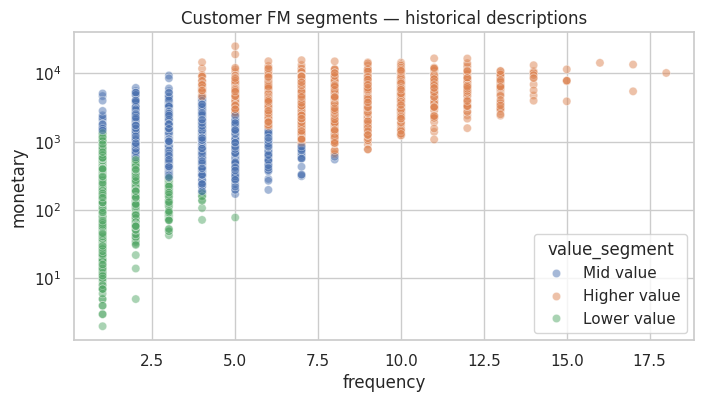

In [21]:
customer = (df.groupby('customer_id')
            .agg(frequency=('order_key', 'nunique'), monetary=('sales', 'sum'),
                 profit=('profit', 'sum')).reset_index())
cluster_inputs = np.log1p(customer[['frequency', 'monetary']].to_numpy())
cluster_scaler = StandardScaler()
cluster_x = cluster_scaler.fit_transform(cluster_inputs)
kmeans = KMeans(n_clusters=3, n_init=20, random_state=SEED)
customer['cluster'] = kmeans.fit_predict(cluster_x)
cluster_order = customer.groupby('cluster').monetary.mean().sort_values().index
cluster_names = dict(zip(cluster_order, ['Lower value', 'Mid value', 'Higher value']))
customer['value_segment'] = customer.cluster.map(cluster_names)
segment_summary = customer.groupby('value_segment').agg(
    customers=('customer_id', 'size'), revenue=('monetary', 'sum'),
    mean_frequency=('frequency', 'mean'))
silhouette = silhouette_score(cluster_x, customer.cluster,
                              sample_size=min(2000, len(customer)), random_state=SEED)
display(segment_summary)
print('Silhouette score:', round(silhouette, 3))
plt.figure(figsize=(8, 4))
sns.scatterplot(data=customer, x='frequency', y='monetary', hue='value_segment', alpha=0.5)
plt.title('Customer FM segments — historical descriptions')
plt.yscale('log')
plt.show()

In [25]:
df

,category,city,country,customer_id,customer_name,discount,market,ji_lu-shu,order_date,order_id,order_priority,product_id,product_name,profit,quantity,region,row_id,sales,segment,ship_date,...,state,sub-category,year,market2,weeknum,original_order_date,original_ship_date,dates_are_synthetic,order_date_method,ship_date_method,month,quarter,estimated_month,estimated_quarter,order_key,product_key,sales_iqr_outlier,log1p_sales,profit_margin,category_code
0,Office Supplies,Los Angeles,United States,LS-172304,Lycoris Saunders,0.0,US,1,2011-01-08,CA-2011-130813,High,OFF-PA-10002005,Xerox 225,9.3312,3,West,36624,19,Consumer,2011-01-12,...,California,Paper,2011,North America,2,2011-01-08,2011-01-12,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,2011-01,1,CA-2011-130813|LS-172304|United States|2011|2,OFF-PA-10002005|Xerox 225,False,2.995732,0.491116,1
1,Office Supplies,Los Angeles,United States,MV-174854,Mark Van Huff,0.0,US,1,2011-01-22,CA-2011-148614,Medium,OFF-PA-10002893,"Wirebound Service Call Books, 5 1/2"" x 4""",9.2928,2,West,37033,19,Consumer,2011-01-26,...,California,Paper,2011,North America,4,2011-01-22,2011-01-26,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,1,1,2011-01,1,CA-2011-148614|MV-174854|United States|2011|4,"OFF-PA-10002893|Wirebound Service Call Books, ...",False,2.995732,0.489095,1
2,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10000659,"Adams Phone Message Book, Professional, 400 Me...",9.8418,3,West,31468,21,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,2011-08,3,CA-2011-118962|CS-121304|United States|2011|32,"OFF-PA-10000659|Adams Phone Message Book, Prof...",False,3.091042,0.468657,1
3,Office Supplies,Los Angeles,United States,CS-121304,Chad Sievert,0.0,US,1,2011-08-06,CA-2011-118962,Medium,OFF-PA-10001144,Xerox 1913,53.2608,2,West,31469,111,Consumer,2011-08-10,...,California,Paper,2011,North America,32,2011-08-06,2011-08-10,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,8,3,2011-08,3,CA-2011-118962|CS-121304|United States|2011|32,OFF-PA-10001144|Xerox 1913,False,4.718499,0.479827,1
4,Office Supplies,Los Angeles,United States,AP-109154,Arthur Prichep,0.0,US,1,2011-10-01,CA-2011-146969,High,OFF-PA-10002105,Xerox 223,3.1104,1,West,32440,6,Consumer,2011-10-05,...,California,Paper,2011,North America,40,2011-10-01,2011-10-05,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,10,4,2011-10,4,CA-2011-146969|AP-109154|United States|2011|40,OFF-PA-10002105|Xerox 223,False,1.945910,0.518400,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51285,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10000632,Satellite Sectional Post Binders,22.5732,2,West,33646,69,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,2014-12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10000632|Satellite Sectional Post Binders,False,4.248495,0.327148,1
51286,Office Supplies,Los Angeles,United States,AM-103604,Alice McCarthy,0.2,US,1,2014-12-03,CA-2014-109701,High,OFF-BI-10004187,Staples,3.1584,6,West,33645,9,Corporate,2014-12-07,...,California,Binders,2014,North America,49,2014-12-03,2014-12-07,True,Jan 1 + 7 * (weeknum - 1); assumed week conven...,Order Date + 4 calendar days; assumed delay,12,4,2014-12,4,CA-2014-109701|AM-103604|United States|2014|49,OFF-BI-10004187|Staples,False,2.302585,0.350933,1
51

## 13. Summarize eight business observations
Every value below is calculated from the current CSV. Suggested actions need further business investigation.
Losses are not deleted, and observed associations do not establish causes.

In [26]:
top_category = category.revenue.idxmax()
sub_profit = df.groupby('sub-category').profit.sum()
worst_sub = sub_profit.idxmin()
loss_lines = df[df.profit < 0]
high = segment_summary.loc['Higher value']
insights = [
    f"Revenue changed by {(annual.revenue.iloc[-1]/annual.revenue.iloc[0]-1)*100:.1f}% from 2011 to 2014; investigate the growth drivers.",
    f"{top_category} contributes {category.loc[top_category, 'revenue']/total_sales*100:.1f}% of revenue; compare its margin too.",
    f"{regions.index[0]} contributes {regions.iloc[0]/total_sales*100:.1f}% of revenue; investigate regional demand.",
    f"{len(loss_lines):,} lines have negative profit ({len(loss_lines)/len(df)*100:.1f}%); combined profit {loss_lines.profit.sum():,.0f}. Review pricing and costs.",
    f"{worst_sub} has the lowest subcategory profit ({sub_profit.loc[worst_sub]:,.0f}); inspect its product mix.",
    f"Higher-value cluster: {int(high.customers):,} customers and {high.revenue/total_sales*100:.1f}% of revenue; consider retention experiments.",
    f"Discount–Profit correlation: {correlation.loc['discount', 'profit']:.3f}. Association is not causation.",
    f"Supplied buckets 40–53 contribute {df.loc[df.weeknum >= 40, 'sales'].sum()/total_sales*100:.1f}% of sales. This does not verify holiday effects."
]
for number, insight in enumerate(insights, 1):
    print(f'{number}. {insight}\n')

1. Revenue changed by 90.3% from 2011 to 2014; investigate the growth drivers.

2. Technology contributes 37.5% of revenue; compare its margin too.

3. Central contributes 22.3% of revenue; investigate regional demand.

4. 12,544 lines have negative profit (24.5%); combined profit -920,646. Review pricing and costs.

5. Tables has the lowest subcategory profit (-64,083); inspect its product mix.

6. Higher-value cluster: 2,279 customers and 78.7% of revenue; consider retention experiments.

7. Discount–Profit correlation: -0.316. Association is not causation.

8. Supplied buckets 40–53 contribute 34.9% of sales. This does not verify holiday effects.



In [27]:
print(df['order_date'])

0       2011-01-08
1       2011-01-22
2       2011-08-06
3       2011-08-06
4       2011-10-01
           ...    
51285   2014-12-03
51286   2014-12-03
51287   2014-12-17
51288   2014-12-24
51289   2014-12-24
Name: order_date, Length: 51290, dtype: datetime64[ns]


In [28]:
df['order_date'] = pd.to_datetime(df['order_date'], errors="coerce")
df["sales"] = pd.to_numeric(df['sales'], errors="coerce")
df = df.dropna(subset=['order_date', 'sales'])
monthly = df.groupby(df['order_date'].dt.to_period("M"))['sales'].sum().sort_index().to_timestamp()
monthly = monthly.asfreq("MS", fill_value=0)
data = pd.DataFrame({'revenue': monthly})
data.index.name = 'month'
display(data.head())

,revenue
month,
2011-01-01,90804
2011-02-01,96207
2011-03-01,128018
2011-04-01,137678
2011-05-01,129714


Create forecasting features
A lag is an earlier month’s revenue. shift(1) ensures that the rolling averages only use past months, preventing target leakage. The 12-month lag means the first year cannot be used as training examples.

In [29]:
for lag in [1, 2, 3, 6, 12]:
    data[f"lag_{lag}"] = data["revenue"].shift(lag)
for window in [3, 6]:
    data[f"rolling_mean_{window}"] = data["revenue"].shift(1).rolling(window).mean()
data["month_number"] = data.index.month
data["month_sin"] = np.sin(2 * np.pi * data.index.month / 12)
data["month_cos"] = np.cos(2 * np.pi * data.index.month / 12)
data["trend"] = np.arange(len(data))
model_data = data.dropna().copy()
features = [c for c in model_data.columns if c != "revenue"]
print("Usable months:", len(model_data))
display(model_data.head())

Usable months: 36


,revenue,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,month_number,month_sin,month_cos,trend
month,,,,,,,,,,,,
2012-01-01,154999,358145.0,282334.0,250455.0,143794.0,90804.0,296978.000000,245596.666667,1,0.500000,8.660254e-01,12
2012-02-01,96559,154999.0,358145.0,282334.0,186246.0,96207.0,265159.333333,247464.166667,2,0.866025,5.000000e-01,13
2012-03-01,147830,96559.0,154999.0,358145.0,252606.0,128018.0,203234.333333,232516.333333,3,1.000000,6.123234e-17,14
2012-04-01,184931,147830.0,96559.0,154999.0,250455.0,137678.0,133129.333333,215053.666667,4,0.866025,-5.000000e-01,15
2012-05-01,199711,184931.0,147830.0,96559.0,282334.0,129714.0,143106.666667,204133.000000,5,0.500000,-8.660254e-01,16


## Split data in chronological order
Use 2012–2013 for model training and 2014 for final testing. Never shuffle a time series.

In [30]:
train = model_data.iloc[:-12]
test = model_data.iloc[-12:]
X_train, y_train = train[features], train["revenue"]
X_test, y_test = test[features], test["revenue"]
print("Training:", train.index.min(), "to", train.index.max(), len(train), "months")
print("Testing:", test.index.min(), "to", test.index.max(), len(test), "months")

Training: 2012-01-01 00:00:00 to 2013-12-01 00:00:00 24 months
Testing: 2014-01-01 00:00:00 to 2014-12-01 00:00:00 12 months


## Define three models and hyperparameter grids
**Linear Regression:** fits a linear relationship. **Random Forest:** averages many decision trees. **XGBoost:** builds trees sequentially to correct errors. Grid search tries different settings for each model.

In [31]:
models = {
    "Linear Regression": (LinearRegression(), {"fit_intercept": [True, False]}),
    "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=1),
                      {"n_estimators": [100, 200], "max_depth": [3, None], "min_samples_leaf": [1, 3]}),
    "XGBoost": (XGBRegressor(objective="reg:squarederror", random_state=42, n_jobs=1, verbosity=0),
                {"n_estimators": [100, 200], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]})
}
cv = TimeSeriesSplit(n_splits=3)

##Tune and evaluate all three models
MAE/RMSE/MAPE: smaller is better. R²: larger is better. CV MAE determines model selection; the untouched final year is used to report generalization.

In [32]:
results = []
predictions = pd.DataFrame({"month": test.index, "actual_revenue": y_test.to_numpy()})
trained_models = {}
for name, (model, parameters) in models.items():
    search = GridSearchCV(model, parameters, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1)
    search.fit(X_train, y_train)
    pred = search.predict(X_test)
    trained_models[name] = search.best_estimator_
    predictions[name.lower().replace(" ", "_") + "_prediction"] = pred
    results.append({
        "Model": name,
        "CV_MAE": -search.best_score_,
        "Test_MAE": mean_absolute_error(y_test, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test_MAPE_pct": mean_absolute_percentage_error(y_test, pred) * 100,
        "Test_R2": r2_score(y_test, pred),
        "Best_Params": str(search.best_params_)
    })
comparison = pd.DataFrame(results).sort_values("CV_MAE").reset_index(drop=True)
display(comparison)

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_MAPE_pct,Test_R2,Best_Params
0,Random Forest,54320.157392,70870.443132,93946.675157,17.340613,0.309866,"{'max_depth': 3, 'min_samples_leaf': 1, 'n_est..."
1,XGBoost,64630.669271,69483.320312,80205.441810,19.813468,0.496988,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
2,Linear Regression,123109.394828,55126.123639,66552.453005,15.481389,0.653663,{'fit_intercept': True}


## Select the model based on validation, not test performance
Choosing based on cross-validation avoids using the test set to make modeling decisions. The test scores may rank models differently.

In [33]:
best_name = comparison.iloc[0]["Model"]
best_model = trained_models[best_name]
print("Selected by lowest time-series CV MAE:", best_name)
print("Lowest holdout test MAE (comparison only):", comparison.sort_values("Test_MAE").iloc[0]["Model"])

Selected by lowest time-series CV MAE: Random Forest
Lowest holdout test MAE (comparison only): Linear Regression


Plot actual versus predicted revenue

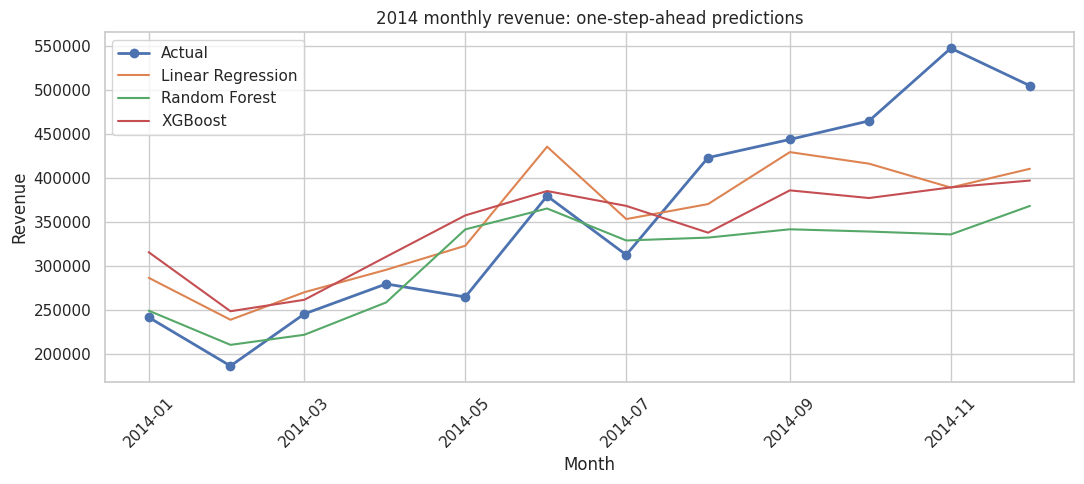

In [34]:
plt.figure(figsize=(11, 5))
plt.plot(test.index, y_test, "o-", label="Actual", linewidth=2)
for name in models:
    plt.plot(test.index, predictions[name.lower().replace(" ", "_") + "_prediction"], label=name)
plt.title("2014 monthly revenue: one-step-ahead predictions")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 11. Save outputs
Download the comparison, predictions, and trained model for use in a report or Power BI.

In [35]:
comparison.to_csv("RevenueVision_Model_Comparison.csv", index=False)
predictions.to_csv("RevenueVision_Test_Predictions.csv", index=False)
joblib.dump({"model": best_model, "features": features, "selected_model": best_name,
             "evaluation_type": "one-step-ahead using observed prior-month sales"}, "RevenueVision_Best_Model.joblib")
print("Files saved.")

Files saved.


## 12. How to explain the results
- **Cross-validation:** checks each candidate on successive past-to-future splits within the training period.
- **Hyperparameter tuning:** finds model settings with the lowest validation MAE.
- **Final test:** evaluates the chosen settings on 2014 months, which were not used for tuning.
- **Limitation 1:** Dates are synthetic and monthly assignments are approximate.
- **Limitation 2:** The test uses actual previous-month revenue as it becomes available, so it represents rolling one-step-ahead forecasting, not a full 12-month-ahead prediction.
- **Limitation 3:** There are only 24 training examples after generating 12-month lag features; results may be unstable. More real historical data would improve reliability.

## 13. Forecast the next 6 months
The earlier test used **known previous-month sales**. Here we predict genuinely future months, one at a time. Each prediction becomes an input for the next month. These are **estimated-date forecasts**, because the project dates are synthetic.

In [36]:
# Start with all known monthly sales, including the test period.
# Refit the selected model on all available months after choosing it by CV.
from sklearn.base import clone
final_model = clone(best_model)
final_model.fit(model_data[features], model_data["revenue"])

history = data["revenue"].copy()  # Keep actual monthly revenue as history
future_rows = []

for step in range(6):
    next_month = history.index[-1] + pd.offsets.MonthBegin(1)
    previous = history.to_numpy()
    # Build the same inputs used in training. Only past information is used.
    inputs = {f"lag_{lag}": previous[-lag] for lag in [1, 2, 3, 6, 12]}
    for window in [3, 6]:
        inputs[f"rolling_mean_{window}"] = previous[-window:].mean()
    inputs["month_number"] = next_month.month
    inputs["month_sin"] = np.sin(2 * np.pi * next_month.month / 12)
    inputs["month_cos"] = np.cos(2 * np.pi * next_month.month / 12)
    inputs["trend"] = len(history)
    next_X = pd.DataFrame([inputs], columns=features)
    predicted = max(0.0, float(final_model.predict(next_X)[0]))
    future_rows.append({"month": next_month, "forecast_revenue": predicted})
    history.loc[next_month] = predicted  # Use prediction for subsequent months

future_forecast = pd.DataFrame(future_rows)
display(future_forecast)


,month,forecast_revenue
0,2015-01-01,387250.414244
1,2015-02-01,282424.911604
2,2015-03-01,369897.737832
3,2015-04-01,397515.684498
4,2015-05-01,399453.209429
5,2015-06-01,463118.812726


## 14. Visualize actual sales and future forecasts
The solid line shows estimated historical monthly sales; the dashed line shows the model forecast. The future values are projections, not observed sales.

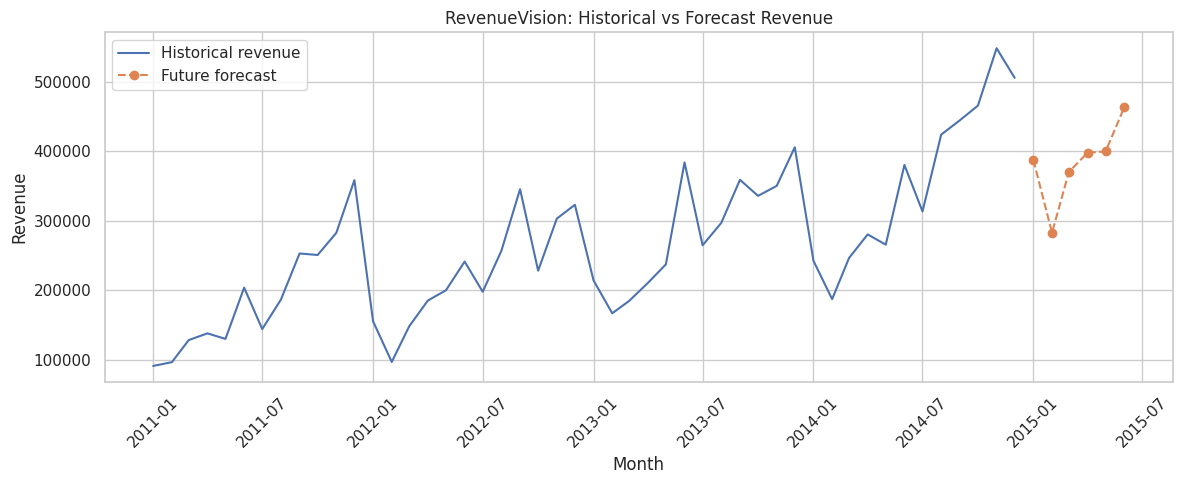

In [37]:
plt.figure(figsize=(12, 5))
plt.plot(data.index, data["revenue"], label="Historical revenue")
plt.plot(future_forecast["month"], future_forecast["forecast_revenue"],
         "o--", label="Future forecast")
plt.title("RevenueVision: Historical vs Forecast Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 15. Simple dashboard: KPIs, categories, regions, and model comparison
This is a **static Matplotlib dashboard**. It covers the main dashboard components in the PDF; a fully interactive Power BI report can be built separately.

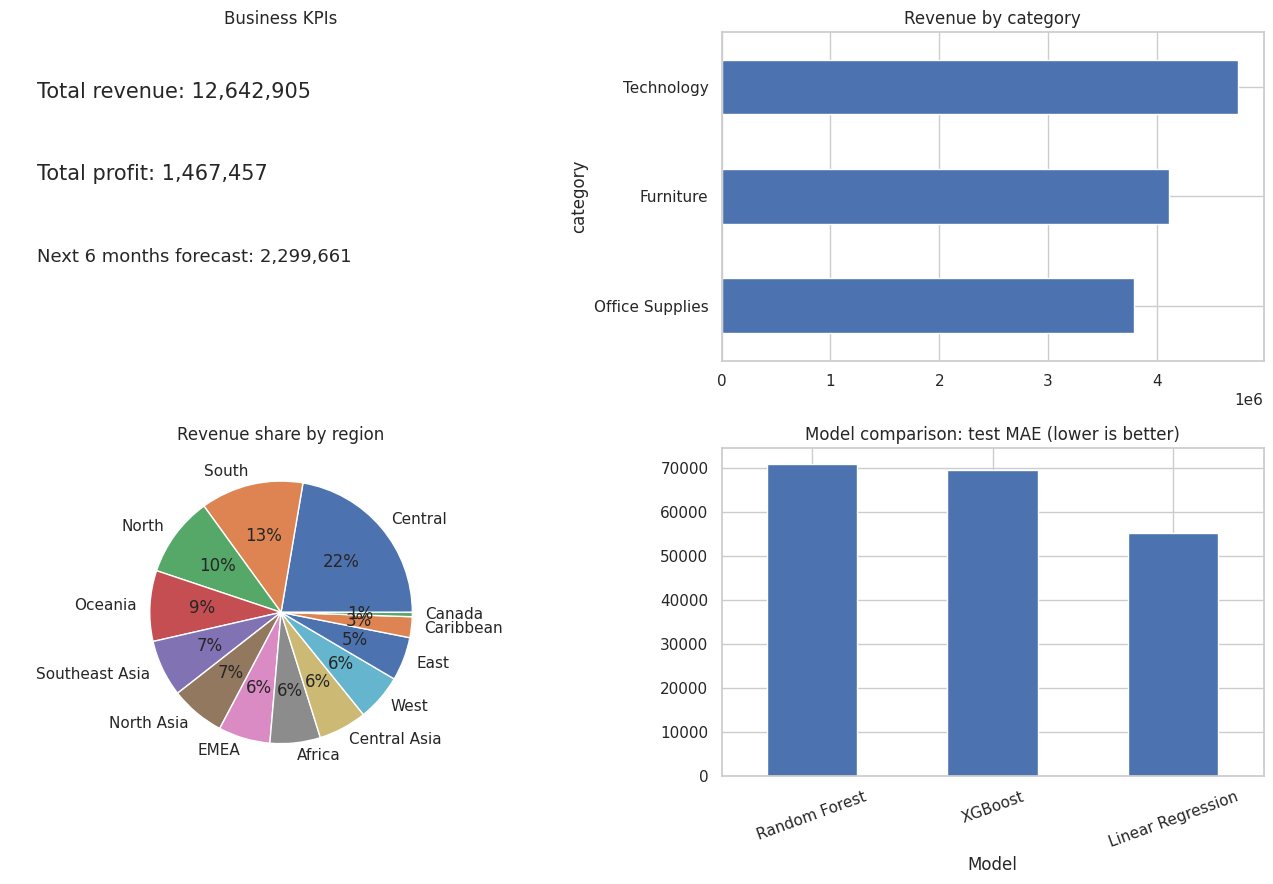

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
# KPI overview
axes[0, 0].axis("off")
axes[0, 0].text(0.05, 0.8, f"Total revenue: {df['sales'].sum():,.0f}", fontsize=15)
axes[0, 0].text(0.05, 0.55, f"Total profit: {df['profit'].sum():,.0f}", fontsize=15)
axes[0, 0].text(0.05, 0.3, f"Next 6 months forecast: {future_forecast['forecast_revenue'].sum():,.0f}", fontsize=13)
axes[0, 0].set_title("Business KPIs")
# Product categories
(df.groupby("category")["sales"].sum().sort_values()).plot.barh(ax=axes[0, 1])
axes[0, 1].set_title("Revenue by category")
# Regional distribution
region_sales = df.groupby("region")["sales"].sum().sort_values(ascending=False)
axes[1, 0].pie(region_sales, labels=region_sales.index, autopct="%1.0f%%")
axes[1, 0].set_title("Revenue share by region")
# Model performance
comparison.set_index("Model")["Test_MAE"].plot.bar(ax=axes[1, 1])
axes[1, 1].set_title("Model comparison: test MAE (lower is better)")
axes[1, 1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


## 16. Automatically explain the main findings
These statements use values calculated from your data, rather than fixed or invented conclusions.

In [39]:
top_region = df.groupby("region")["sales"].sum().idxmax()
top_category = df.groupby("category")["sales"].sum().idxmax()
profit_margin = 100 * df["profit"].sum() / df["sales"].sum()
print("BUSINESS SUMMARY")
print(f"1. Total revenue: {df['sales'].sum():,.2f}")
print(f"2. Total profit: {df['profit'].sum():,.2f}")
print(f"3. Overall profit margin: {profit_margin:.2f}%")
print(f"4. Highest-revenue region: {top_region}")
print(f"5. Highest-revenue category: {top_category}")
print(f"6. Selected model (by validation MAE): {best_name}")
print(f"7. Forecast revenue for next 6 months: {future_forecast['forecast_revenue'].sum():,.2f}")
print(f"8. Forecast for first future month: {future_forecast.iloc[0]['forecast_revenue']:,.2f}")
print("Reminder: estimated dates limit calendar-based business interpretation.")


BUSINESS SUMMARY
1. Total revenue: 12,642,905.00
2. Total profit: 1,467,457.29
3. Overall profit margin: 11.61%
4. Highest-revenue region: Central
5. Highest-revenue category: Technology
6. Selected model (by validation MAE): Random Forest
7. Forecast revenue for next 6 months: 2,299,660.77
8. Forecast for first future month: 387,250.41
Reminder: estimated dates limit calendar-based business interpretation.
